# Ejercicio de limpieza y transformación de los datos
Sobre el dataset merged_df aplicaremos una serie de transformaciones para poder dejar un dataset listo para la selección de variables y el futuro entrenamiento de los modelo.

## Librerias y Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("../data/merged_df.csv")
display(df.head())

,encounter_id,patient_id,encounter_type,admission_datetime,discharge_datetime,length_of_stay_days,admission_urgency,department,attending_physician_id,icu_admitted,icu_days,discharge_disposition,news2_acuity_score,revisit_count,previous_encounter_id,days_since_last_discharge,readmission_30d,in_hospital_mortality,clinical_record_id,primary_diagnosis_code,primary_diagnosis_name,disease_category,disease_severity,secondary_diagnosis_code,systolic_bp_mmhg,...,claim_denial_reason,first_name,last_name,gender,date_of_birth,age,blood_group,marital_status,race_ethnicity,residential_zone,socioeconomic_tier,primary_insurance_provider,insurance_policy_id,contact_phone,emergency_contact_phone,street_address,zip_code,baseline_bmi,smoker_status,baseline_charlson_comorbidity_index,registration_date,n_meds,n_high_risk_meds,total_drug_cost,patient_copay_drugs
0,ENC-100001,PAT-10001,Emergency,2023-03-30 00:00:00,2023-04-03 07:12:00,4.3000,Emergency,General Medicine,DOC-106,0,0.0000,Skilled Nursing Facility,1,1,NaN,NaN,0,0,CLN-100001,N39.0,Urinary Tract Infection with Pyelonephritis,Renal,Mild,E78.5,119.7000,...,Timely Filing Limit Exceeded,Mark,Johnson,Male,1945-11-05,77,O+,Married,Hispanic,Suburban,High,Medicare,INS-887201,533-521-8196x001,790.683.8637x94026,51161 Abbott Rapids,35172,35.7000,Former,1,2021-10-02,3,0,100.7200,18.1300
1,ENC-100002,PAT-10001,Outpatient,2023-04-06 12:00:00,2023-04-06 16:19:12,0.1800,Elective,General Medicine,DOC-151,0,0.0000,Home,2,2,ENC-100001,3.2000,0,0,CLN-100002,J44.1,COPD with Acute Exacerbation,Respiratory,Moderate,N18.3,118.5000,...,NaN,Mark,Johnson,Male,1945-11-05,77,O+,Married,Hispanic,Suburban,High,Medicare,INS-887201,533-521-8196x001,790.683.8637x94026,51161 Abbott Rapids,35172,35.7000,Former,1,2021-10-02,1,0,56.4000,10.1500
2,ENC-100003,PAT-10001,Outpatient,2023-04-18 04:19:12,2023-04-18 13:55:12,0.4000,Elective,Cardiology,DOC-111,0,0.0000,Home,9,3,ENC-100002,11.5000,1,0,CLN-100003,I50.9,"Congestive Heart Failure, Unspecified",Cardiovascular,Severe,E78.5,129.0000,...,NaN,Mark,Johnson,Male,1945-11-05,77,O+,Married,Hispanic,Suburban,High,Medicare,INS-887201,533-521-8196x001,790.683.8637x94026,51161 Abbott Rapids,35172,35.7000,Former,1,2021-10-02,1,0,14.4000,2.5900
3,ENC-100004,PAT-10002,Emergency,2023-03-28 00:00:00,2023-04-07 19:12:00,10.8000,Emergency,Cardiology,DOC-115,0,0.0000,Home,7,1,NaN,NaN,1,0,CLN-100004,I21.9,Acute Myocardial Infarction,Cardiovascular,Severe,I10,150.8000,...,NaN,Renee,Blair,Female,1982-12-16,40,B-,Married,Caucasian,Suburban,Middle,Self-Pay,NaN,+1-516-318-4959,NaN,3419 Amanda Gardens Apt. 764,84387,30.0000,Never,3,2021-08-24,1,0,4.7300,4.7300
4,ENC-100005,PAT-10002,Inpatient,2023-04-09 12:00:00,2023-04-12 16:48:00,3.2000,Urgent,General Medicine,DOC-134,0,0.0000,Home,0,2,ENC-100004,1.7000,1,0,CLN-100005,J18.9,Community-Acquired Pneumonia,Respiratory,Mild,E66.0,120.9000,...,NaN,Renee,Blair,Female,1982-12-16,40,B-,Married,Caucasian,Suburban,Middle,Self-Pay,NaN,+1-516-318-4959,NaN,3419 Amanda Gardens Apt. 764,84387,30.0000,Never,3,2021-08-24,3,0,89.5500,89.5500


### Eliminar Columnas Innecesarias

Se eliminarán 5 tipos de columnas:

-`columnas_info_posterior` : No nos interesa porque tienen data que fue posterior a la atención hospitalaria.

-`columnas_id` : Columnas que contienen identificadores o datos que no aportan al entrenamiento del modelo.

-`columnas_info_nula` : Columnas que tienen demasiados datos nulos.

-`columnas_fechas` : No haremos modelos de series de tiempo por lo cual no nos interesan las fechas.



In [3]:
columnas_info_posterior = [
    "discharge_disposition",     
    "readmission_30d",            
    "days_since_last_discharge", 
    "previous_encounter_id",      
]

columnas_id = [
    "encounter_id", "patient_id", "clinical_record_id", "bill_id",
    "attending_physician_id", "insurance_policy_id",
    "first_name", "last_name", "contact_phone", "emergency_contact_phone",
    "street_address", "zip_code"
]

columnas_info_nula = [
    "primary_diagnosis_code", "primary_diagnosis_name",
    "secondary_diagnosis_code",
    "primary_procedure_code", "primary_procedure_name",
    "claim_denial_reason"          
]

columnas_fechas = [
    "admission_datetime", "discharge_datetime",
    "billing_date", "date_of_birth", "registration_date"
]
cols_a_eliminar = columnas_info_posterior + columnas_id + columnas_info_nula + columnas_fechas
df_clean = df.drop(columns=cols_a_eliminar, errors="ignore")

print(f"Columnas eliminadas: {len(cols_a_eliminar)}")

Columnas eliminadas: 27


### Revisión de valores faltantes

procedure_complexity              42.7900
baseline_bmi                       6.3800
blood_glucose_mg_dl                6.2300
white_blood_cell_count             6.0700
discount_contractual_adjustment    5.8700
spo2_percent                       5.7100
serum_creatinine_mg_dl             5.7100
hemoglobin_g_dl                    5.1000
smoker_status                      4.9000
dtype: float64


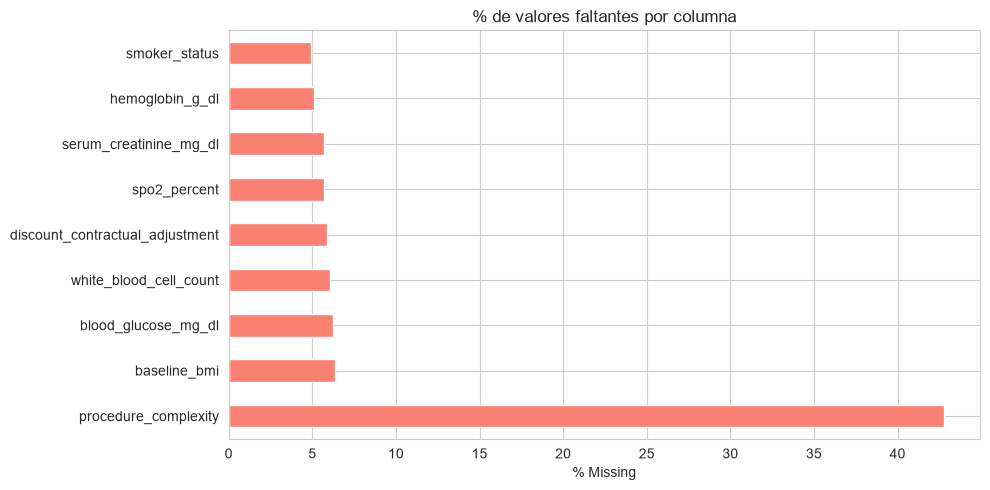

In [4]:
missing = (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)


if len(missing) > 0:
    plt.figure(figsize=(10, 5))
    missing.plot(kind="barh", color="salmon")
    plt.title("% de valores faltantes por columna")
    plt.xlabel("% Missing")
    plt.tight_layout()
    plt.show()

In [5]:
# A las columnas numéricas le asignaremos la mediana
numeric_cols = df_clean.select_dtypes(include=["float64", "int64"]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c != "in_hospital_mortality"] 

for col in numeric_cols:
    if df_clean[col].isnull().any():
        median_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_val)



In [6]:
# A las columnas categóricas le asignaremos "Unknown"
cat_cols = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()

for col in cat_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna("Unknown")

C:\Users\Yepes Zuleta\AppData\Local\Temp\ipykernel_33708\2380765106.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()


In [8]:
print(f"Shape final: {df_clean.shape}")
print(f"Missing totales: {df_clean.isnull().sum().sum()}")
print(f"Duplicados: {df_clean.duplicated().sum()}")

Shape final: (13214, 51)
Missing totales: 0
Duplicados: 0


In [10]:
#Exportar el excel
df_clean.to_csv("../data/df_final.csv", index=False)